In [ ]:
pip install iTransformer optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 7.0 MB/s eta 0:00:00


In [ ]:
#pip install --upgrade --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Colab Notebooks/data/"

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv(path+"BTCUSDT.csv", sep='|')
df = df.rename(columns={'1502942400': 'timestamp', '4261.48': 'open', '4261.48.1': 'high', '4261.48.2': 'low', '4261.48.3': 'close', '1.775183': 'btc_volume_sell', '320.390851': 'usd_volume_buy', '0.075183': 'btc_volume_buy', '7564.906851': 'usd_volume_sell', '3': 'activity'})

df

,timestamp,open,high,low,close,btc_volume_sell,usd_volume_buy,btc_volume_buy,usd_volume_sell,activity
0,1502942460,4261.48,4261.48,4261.48,4261.48,0.000000,0.000000,0.000000,0.000000,0
1,1502942520,4280.56,4280.56,4280.56,4280.56,0.261074,1117.542921,0.261074,1117.542921,2
2,1502942580,4261.48,4261.48,4261.48,4261.48,0.012008,51.171852,0.012008,51.171852,3
3,1502942640,4261.48,4261.48,4261.48,4261.48,0.140796,599.999338,0.140796,599.999338,1
4,1502942700,4261.48,4261.48,4261.48,4261.48,0.000000,0.000000,0.000000,0.000000,0
...,...,...,...,...,...,...,...,...,...,...
3927272,1739092440,97019.80,97019.80,97010.87,97010.88,2.240830,85665.477260,0.883000,217398.976800,566
3927273,1739092500,97010.88,97010.88,96958.32,96958.33,2.732930,61606.259450,0.635210,265051.749220,1807
3927274,1739092560,96958.32,96960.09,96955.60,96960.08,4.747940,322705.228800,3.328320,460349.283670,856
3927275,1739092620,96960.08,96960.09,96948.31,96948.32,1.558250,15319.539770,0.158000,151085.755800,560


##Derive volatility

In [ ]:
import numpy as np

# volatility
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df.set_index('datetime', inplace=True)
df['log_return'] = np.log(df['close'] / df['close'].shift(1))
window_size = 30 * 60 * 60
df['30d_volatility'] = df['log_return'].rolling(window=window_size).std() * np.sqrt(window_size)
df[['close', 'log_return', '30d_volatility']].tail(10)

# avg volume, avg buy volume, avg sell volume
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df.set_index('datetime', inplace=True)
df['usd_total_volume'] = df['usd_volume_buy'] + df['usd_volume_sell']
df['7d_usd_volume_buy_avg'] = df['usd_volume_buy'].rolling(window=7*24*60, center=False).mean()
df['7d_usd_volume_sell_avg'] = df['usd_volume_sell'].rolling(window=7*24*60, center=False).mean()
df['7d_usd_volume_avg'] = df['usd_total_volume'].rolling(window=7*24*60, center=False).mean()

max_vol = max(df[df['30d_volatility'].notna()]['30d_volatility'])
print(max_vol)

window = 4 * 60
#first value most important, last
df['forward_usd_volume_buy_avg'] =  df['usd_volume_buy'].ewm(span=window, adjust=False).mean()
df['forward_usd_volume_sell_avg'] =  df['usd_volume_sell'].ewm(span=window, adjust=False).mean()
df['forward_usd_volume_avg'] =  df['usd_total_volume'].ewm(span=window, adjust=False).mean()

# Calculate 1-hour price change
df['price_change_1h'] = df['close'].diff(periods=60) # Assuming data is in 1-minute intervals, 60 periods = 1 hour
df['price_change_4h'] = df['close'].diff(periods=4*60) # Assuming data is in 1-minute intervals, 60 periods = 1 hour

df['price_change_4h_tanh'] = np.tanh(df['price_change_4h'])
df['price_change_4h_volatility_tanh'] = np.tanh(df['price_change_4h'] * (max_vol - df['30d_volatility']))

df['price_change_4h_ema'] = df['price_change_4h_tanh'].ewm(span=60, adjust=False).mean()
df['price_change_4h_volatility_ema'] = df['price_change_4h_volatility_tanh'].ewm(span=60, adjust=False).mean()


df[['close','usd_volume_buy', 'forward_usd_volume_buy_avg', '7d_usd_volume_buy_avg', 'price_change_1h']] # Display price_change_1h

0.9900359831658481


,close,usd_volume_buy,forward_usd_volume_buy_avg,7d_usd_volume_buy_avg,price_change_1h
datetime,,,,,
2017-08-17 04:01:00,4261.48,0.000000,0.000000,NaN,NaN
2017-08-17 04:02:00,4280.56,1117.542921,9.274215,NaN,NaN
2017-08-17 04:03:00,4261.48,51.171852,9.621913,NaN,NaN
2017-08-17 04:04:00,4261.48,599.999338,14.521311,NaN,NaN
2017-08-17 04:05:00,4261.48,0.000000,14.400802,NaN,NaN
...,...,...,...,...,...
2025-02-09 09:14:00,97010.88,85665.477260,260452.343889,1.075860e+06,-202.14
2025-02-09 09:15:00,96958.33,61606.259450,258802.168915,1.075811e+06,-223.55
2025-02-09 09:16:00,96960.08,322705.228800,259332.484765,1.075826e+06,-266.34


## Sum split for transformers

In [ ]:
import pandas as pd

# Assume df is already loaded and indexed by datetime
# Resample to 1-hour intervals (e.g., using 'close' price)
df_hourly = df.resample('1h').agg({
    'price_change_1h': 'last',
    'close': 'last',
    'usd_volume_buy': 'sum',
    'usd_volume_sell': 'sum'
}).dropna()

# Select last year for validation
last_year = df_hourly.index.max() - pd.Timedelta(days=365)
train_df = df_hourly[df_hourly.index < last_year]
val_df = df_hourly[df_hourly.index >= last_year]

import numpy as np

def create_sequences(data_df, target_column, seq_length):
    X, y = [], []
    data = data_df.values # Use all columns as features
    target_data = data_df[target_column].values
    for i in range(len(data_df) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(target_data[i+seq_length])
    return np.array(X), np.array(y)

seq_length = 24*7  # Use past 7 days (168 hours) to predict next hour
X_train, y_train = create_sequences(train_df, 'price_change_1h', seq_length)
X_val, y_val = create_sequences(val_df, 'price_change_1h', seq_length)

## Traqnsformers

In [ ]:
class FeatureAttention(nn.Module):
    def __init__(self, num_variates):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(num_variates, num_variates),
            nn.ReLU(),
            nn.Linear(num_variates, num_variates),
            nn.Softmax(dim=-1)   # outputs importance weights that sum to 1
        )

    def forward(self, x):
        # x: [batch, seq_len, num_variates]
        # compute weights per batch
        weights = self.attn(x.mean(dim=1))  # aggregate across time
        # apply weights to each feature
        return x * weights.unsqueeze(1)

## Hyperparameter Tuning with Optuna

In [ ]:
import torch, sys, os
print("torch", torch.__version__)
print("torch.cuda.is_available()", torch.cuda.is_available())
print("cuda runtime version:", torch.version.cuda)
print("cuda device count:", torch.cuda.device_count())
if torch.cuda.device_count()>0:
    dev = torch.cuda.get_device_properties(0)
    print("device:", dev.name, "capability:", dev.major, dev.minor, "total mem (GB):", dev.total_memory/1024**3)
import subprocess
print("nvidia-smi:")
!nvidia-smi

torch 2.8.0+cu126
torch.cuda.is_available() True
cuda runtime version: 12.6
cuda device count: 1
device: Tesla T4 capability: 7 5 total mem (GB): 14.74127197265625
nvidia-smi:
Sat Oct  4 22:12:40 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       2MiB /

In [ ]:
import optuna
import torch
import torch.nn as nn
from iTransformer import iTransformer
from sklearn.model_selection import train_test_split
from torch.cuda.amp import autocast

torch.cuda.empty_cache()


def objective(trial):
    dim = trial.suggest_categorical("dim", [32, 64, 128, 256])
    depth = trial.suggest_int("depth", 2, 6)
    heads = trial.suggest_categorical("heads", [4, 8, 16, 32])
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    batch_size = 2048 #trial.suggest_categorical("batch_size", [64, 128, 256, 512])


    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    num_variates = X_train.shape[-1]
    lookback_len = seq_length
    pred_length = 1

    subset_size = 5000
    X_train_tensor_subset = torch.tensor(X_train[:subset_size], dtype=torch.float32).to(device)
    y_train_tensor_subset = torch.tensor(y_train[:subset_size], dtype=torch.float32).to(device)
    X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
    y_val_tensor = torch.tensor(y_val, dtype=torch.float32).to(device)


    # Define iTransformer model with suggested hyperparameters
    model = iTransformer(
        num_variates = num_variates,
        lookback_len = lookback_len,
        dim = dim,
        depth = depth,
        heads = heads,
        dim_head = 32,
        pred_length = pred_length,
        num_tokens_per_variate = 1,
        use_reversible_instance_norm = False # Set to False
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    loss_fn = nn.HuberLoss()

    epochs = 5
    train_data = torch.utils.data.TensorDataset(X_train_tensor_subset, y_train_tensor_subset)
    train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)

    close_col_index = df_hourly.columns.get_loc('price_change_1h')

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        for batch_X, batch_y in train_loader:
            output = model(batch_X)
            output_close = output[:, :, close_col_index].squeeze()
            loss = loss_fn(output_close, batch_y)
            loss.backward()
            optimizer.step()


    # Evaluate on validation set
    model.eval()
    with torch.no_grad():
        val_loss = 0
        val_data = torch.utils.data.TensorDataset(X_val_tensor, y_val_tensor)
        val_loader = torch.utils.data.DataLoader(val_data, batch_size=batch_size)
        for batch_X_val, batch_y_val in val_loader:
            output = model(batch_X_val)
            # Select the prediction for the 'close' price
            output_close = output[:, :, close_col_index].squeeze()
            val_loss += loss_fn(output_close, batch_y_val).item()


    avg_val_loss = val_loss / len(val_loader)

    return avg_val_loss

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

print("Best hyperparameters: ", study.best_params)

[I 2025-10-04 22:16:59,026] A new study created in memory with name: no-name-a8570965-8c9e-4f52-a513-846a90528af3
[I 2025-10-04 22:17:01,792] Trial 0 finished with value: 464.173828125 and parameters: {'dim': 128, 'depth': 4, 'heads': 4, 'lr': 0.00010314234236296656}. Best is trial 0 with value: 464.173828125.
[I 2025-10-04 22:17:06,118] Trial 1 finished with value: 361.864111328125 and parameters: {'dim': 32, 'depth': 4, 'heads': 32, 'lr': 0.0014317590798897455}. Best is trial 1 with value: 361.864111328125.
[I 2025-10-04 22:17:09,865] Trial 2 finished with value: 6102.9478515625 and parameters: {'dim': 128, 'depth': 6, 'heads': 4, 'lr': 3.091098072714387e-05}. Best is trial 1 with value: 361.864111328125.
[I 2025-10-04 22:17:13,077] Trial 3 finished with value: 358.3751525878906 and parameters: {'dim': 128, 'depth': 4, 'heads': 8, 'lr': 0.0002735864172445991}. Best is trial 3 with value: 358.3751525878906.
[I 2025-10-04 22:17:15,409] Trial 4 finished with value: 290.65264587402345 an

Best hyperparameters:  {'dim': 64, 'depth': 2, 'heads': 16, 'lr': 0.009526087003989034}


In [ ]:
import torch
from iTransformer import iTransformer
import numpy as np # Import numpy

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)
torch.cuda.empty_cache()

num_variates = X_train.shape[-1]
lookback_len = seq_length      # past hours # Corrected lookback_len
pred_length = 1        # predict next hour


# Convert numpy arrays to torch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).to(device)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).to(device)

# Define iTransformer model with best hyperparameters from the study
best_params = study.best_params
model = iTransformer(
    num_variates = num_variates,
    lookback_len = lookback_len,
    dim = best_params['dim'],
    depth = best_params['depth'],
    heads = best_params['heads'],
    dim_head = 32,
    pred_length = pred_length,
    num_tokens_per_variate = 1,
    use_reversible_instance_norm = True
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=best_params['lr'])
loss_fn = torch.nn.HuberLoss()

subset_size = len(X_train_tensor) #min(len(X_train_tensor), 50000) # Adjusted subset_size for OOM
print(len(X_train_tensor) )
X_train_tensor_subset = X_train_tensor[:subset_size]
y_train_tensor_subset = y_train_tensor[:subset_size]


batch_size = 2048
train_data = torch.utils.data.TensorDataset(X_train_tensor_subset, y_train_tensor_subset)
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)

# Gradient Accumulation
accumulation_steps = 4 # Accumulate gradients over 4 batches

close_col_index = df_hourly.columns.get_loc('price_change_1h')

epochs = 1000
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for i, (batch_X, batch_y) in enumerate(train_loader):
        output = model(batch_X)
        output_price_change = output[:, :, close_col_index].squeeze()
        loss = loss_fn(output_price_change, batch_y)

        loss = loss / accumulation_steps
        loss.backward()

        if (i + 1) % accumulation_steps == 0:
            optimizer.step()
            optimizer.zero_grad()

        total_loss += loss.item() * accumulation_steps

    if len(train_loader) % accumulation_steps != 0:
        optimizer.step()
        optimizer.zero_grad()


    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.6f}")

# Validation
model.eval()
with torch.no_grad():
    val_pred = model(X_val_tensor).cpu().numpy().squeeze()

import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.plot(y_val.cpu().numpy(), label='Actual') # Move to CPU for plotting
plt.plot(val_pred, label='Predicted')
plt.legend()
plt.title('iTransformer 1-hour Step Prediction (Last Year)')
plt.show()

created = True

cpu


NameError: name 'study' is not defined

## Check results

In [ ]:
import os
import torch
from iTransformer import iTransformer

try:
  created
except:
  # Create a filename based on the best hyperparameters
  # best_params = study.best_params # Make sure best_params is accessible here
  # param_string = "_".join([f"{key}-{value}" for key, value in best_params.items()])
  model_path = f'itransformer_model_params_dim-64_depth-2_heads-16_lr-0.009526087003989034.pth'
  device = 'cuda' if torch.cuda.is_available() else 'cpu'

  # Save the model's state dictionary
  #torch.save(model.state_dict(), model_path)
  #print(f"Model saved to {model_path}")

  loaded_model = iTransformer(
      num_variates = 4, # Assuming num_variates is available
      lookback_len = 24*7, # Assuming seq_length is available
      dim = 64,
      depth = 2,
      heads = 16,
      dim_head = 32, # Assuming dim_head was fixed or can be parsed if included in filename
      pred_length = 1, # Assuming pred_length is available
      num_tokens_per_variate = 1, # Assuming num_tokens_per_variate is fixed
      use_reversible_instance_norm = True # Ensure this matches the saved model's config
  ).to(device) # Assuming device is available


  # Load the saved state dictionary
  loaded_model.load_state_dict(torch.load(model_path, map_location=torch.device(device)))
  loaded_model.eval() # Set the loaded model to evaluation mode
  model = loaded_model

  X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)

  print(f"Model loaded from {model_path}")

Model loaded from itransformer_model_params_dim-64_depth-2_heads-16_lr-0.009526087003989034.pth


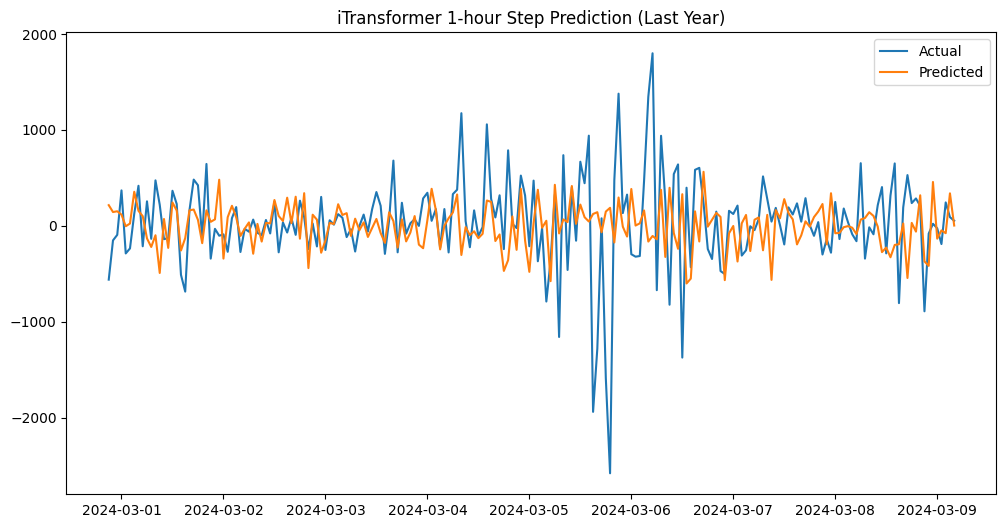

[array([ -63.61,   45.27,  -31.19, ...,   51.94,   28.17, -285.83]),
 array([  85.7952 ,   75.18493,  153.20844, ..., -243.01537,  122.05087,
          83.11548], dtype=float32)]

In [ ]:
# Validation
model.eval()
with torch.no_grad():
    val_pred = model(X_val_tensor).cpu().numpy().squeeze()

# Select the prediction for the 'close' price
# This assumes the order of columns in X_val is the same as df_hourly
close_col_index = df_hourly.columns.get_loc('price_change_1h')
val_pred_1h_change = val_pred[:, close_col_index]


import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
# Use the datetime index from df_hourly for the x-axis
plt.plot(df_hourly.index[len(df_hourly)-len(y_val):][300:500], y_val[300:500], label='Actual')
plt.plot(df_hourly.index[len(df_hourly)-len(val_pred_1h_change):][300:500], val_pred_1h_change[300:500], label='Predicted')
plt.legend()
plt.title('iTransformer 1-hour Step Prediction (Last Year)')
plt.show()

[y_val, val_pred_1h_change]

In [ ]:
del X_train_tensor
del y_train_tensor
del X_val_tensor
del y_val_tensor
torch.cuda.empty_cache()

NameError: name 'X_train_tensor' is not defined

In [ ]:
import pandas as pd


val_pred_ex = val_pred[:, close_col_index]
close_price = df_hourly['close'][len(df_hourly['close'])-len(y_val):]
comparison_df = pd.DataFrame({'Actual': y_val, 'Predicted': val_pred_ex, 'Diff:':val_pred_ex-y_val, 'close_price':close_price})
comparison_df['Actual_vs_Previous_Actual'] = comparison_df['Actual'].diff()
display(comparison_df)

,Actual,Predicted,Diff:,close_price,Actual_vs_Previous_Actual
datetime,,,,,
2024-02-17 09:00:00,-63.61,85.795197,149.405197,51676.40,NaN
2024-02-17 10:00:00,45.27,75.184929,29.914929,51721.67,108.88
2024-02-17 11:00:00,-31.19,153.208435,184.398435,51690.48,-76.46
2024-02-17 12:00:00,20.62,15.334203,-5.285797,51711.10,51.81
2024-02-17 13:00:00,-522.29,130.239914,652.529914,51188.81,-542.91
...,...,...,...,...,...
2025-02-09 05:00:00,-191.31,224.591553,415.901553,97029.28,-111.90
2025-02-09 06:00:00,-23.39,278.903748,302.293748,97005.89,167.92
2025-02-09 07:00:00,51.94,-243.015366,-294.955366,97057.83,75.33


/tmp/ipython-input-4201872226.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  predicted_price = hourly_price[i-1] + predicted_changes[i]
/tmp/ipython-input-4201872226.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  predicted_pct_change = (predicted_price - hourly_price[i-1]) / hourly_price[i-1]
/tmp/ipython-input-4201872226.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  actual_pct_change = (hourly_price[i] - hourly_p

Optimal Profit Threshold: 0.54%
13259.785933301288


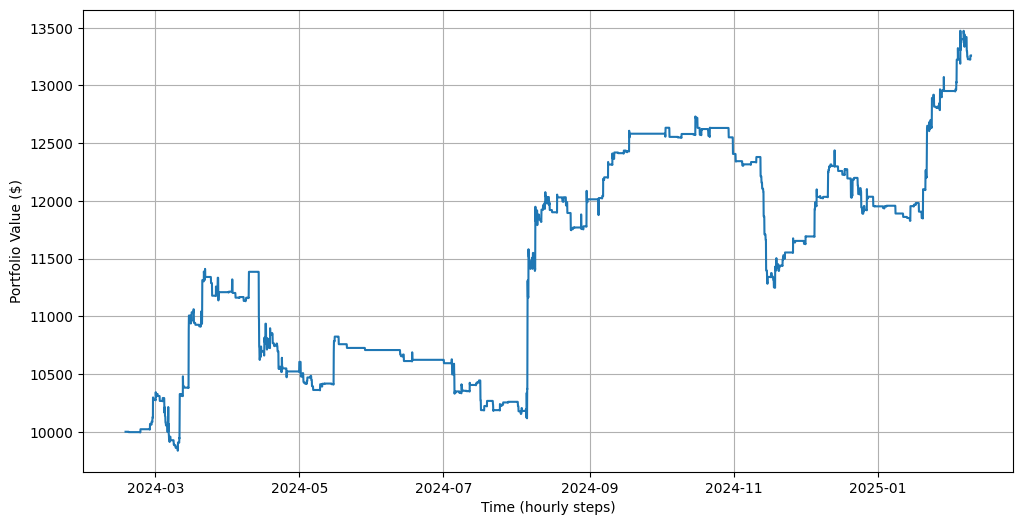

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def backtest_profit_threshold(hourly_price, predicted_changes, initial_capital=10000, threshold=0.01, transaction_cost_pct=0.1):
    capital = initial_capital
    portfolio_values = [capital]
    position = 0  # 1 = long, -1 = short
    entry_price = 0  # price at which position was opened
    threshold /= 100
    transaction_cost = transaction_cost_pct / 100

    for i in range(1, len(hourly_price)):
        predicted_price = hourly_price[i-1] + predicted_changes[i]
        predicted_pct_change = (predicted_price - hourly_price[i-1]) / hourly_price[i-1]
        actual_pct_change = (hourly_price[i] - hourly_price[i-1]) / hourly_price[i-1]

        if position != 0:
             capital *= (1 + position * actual_pct_change)

        if position == 0:
            if predicted_pct_change > threshold:
                position = 1
                entry_price = hourly_price[i-1]
                capital *= (1 - transaction_cost) # Subtract transaction cost
            elif predicted_pct_change < -threshold:
                position = -1
                entry_price = hourly_price[i-1]
                capital *= (1 - transaction_cost) # Subtract transaction cost

        elif position == 1:
            if actual_pct_change < threshold: # Exit condition
                position = 0
        elif position == -1:
            if actual_pct_change > -threshold: # Exit condition
                position = 0


        portfolio_values.append(capital)

    return portfolio_values


best_threshold = 0
initial_capital = 10000
best_final_capital = initial_capital
fixed_transaction_cost_pct = 0.0275

for threshold in np.arange(0.01, 1.01, 0.01):
    portfolio_values = backtest_profit_threshold(close_price, val_pred_1h_change, initial_capital, threshold, fixed_transaction_cost_pct)
    if portfolio_values[-1] > best_final_capital:
        best_final_capital = portfolio_values[-1]
        best_threshold = threshold

print(f"Optimal Profit Threshold: {best_threshold:.2f}%")

portfolio_history_optimal = backtest_profit_threshold(close_price, val_pred_1h_change, initial_capital, best_threshold, fixed_transaction_cost_pct)
print(portfolio_history_optimal[-1])

import matplotlib.pyplot as plt

# Get the datetime index corresponding to the length of portfolio_history_optimal
plot_index = df_hourly.index[len(df_hourly)-len(portfolio_history_optimal):]

plt.figure(figsize=(12, 6))
plt.plot(plot_index, portfolio_history_optimal) # Use plot_index for the x-axis
#plt.title(f'Portfolio Value Over Time (Buy Threshold: {best_threshold:.2f}%, Transaction Cost: {fixed_transaction_cost_pct}%)')
plt.xlabel('Time (hourly steps)')
plt.ylabel('Portfolio Value ($)')
plt.grid(True)
plt.show()

Streaming output truncated to the last 5000 lines.
v: 0.004537168134375792 raw: 5.223522536102922 res: 1.0
v: 0.002906537363285591 raw: 8.154032457786535 res: 1.0
v: 0.00362221296952782 raw: 6.5429614987794205 res: 1.0
v: 0.00380013045091271 raw: 6.236628006890598 res: 1.0
v: 0.005120843683223907 raw: 4.62814361579561 res: 1.0
v: 0.008617997010722162 raw: 2.7500589719993433 res: 1.0
v: 0.008671655473578852 raw: 2.7330421592751364 res: 1.0
v: 0.00872841052350303 raw: 2.7152710033725964 res: 1.0
v: 0.006068199000459652 raw: 3.9056069186598497 res: 1.0
v: 0.005434268922171563 raw: 4.36121221445356 res: 1.0
v: 0.005418971860110566 raw: 4.373523356793449 res: 1.0
v: 0.005887908342791909 raw: 4.025198528950268 res: 1.0
v: 0.005676920233374106 raw: 4.174798839108188 res: 1.0
v: 0.005938991629535888 raw: 3.9905764275091387 res: 1.0
v: 0.0038762430998476186 raw: 6.114167607530004 res: 1.0
v: 0.003639953019560809 raw: 6.511073047547082 res: 1.0
v: 0.006665256856777966 raw: 3.5557519401370463 res

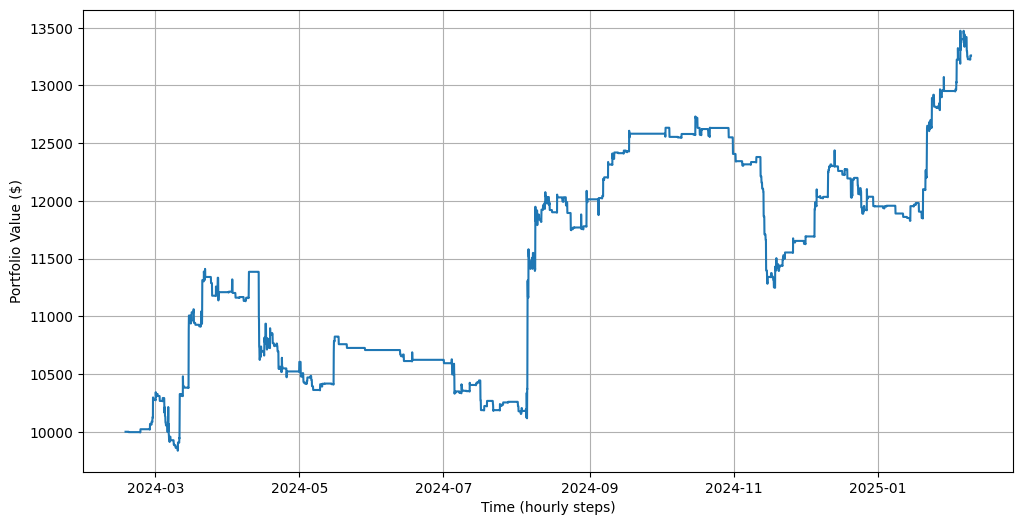

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def backtest_profit_threshold(hourly_price,
                              predicted_changes,
                              initial_capital=10000,
                              threshold=0.01,
                              vol_window=24,
                              target_risk_per_trade=0.5,
                              transaction_cost=0.1,
                              min_size=0.05,
                              max_size=1.0):
    threshold /= 100.0
    target_risk_per_trade /= 100.0
    transaction_cost /= 100.0
    prices = np.asarray(hourly_price)
    preds = np.asarray(predicted_changes)

    # Realized volatility (rolling standard deviations of returns)
    returns = np.diff(prices) / prices[:-1]
    vol_series = pd.Series(returns).rolling(vol_window).std().to_numpy()
    vol_series = np.concatenate([[0], vol_series])

    capital = initial_capital
    portfolio_values = [capital]

    position = 0          # 1 long, -1 short, 0 - no position
    position_size = 0.0   # fraction of capital
    entry_price = 0.0

    def size_from_vol(v):
        if np.isnan(v) or v < 1e-8:
            v = 0.01  # fallback volatility
        raw = target_risk_per_trade / v

        res = float(np.clip(raw, min_size, max_size)) # do not exceed min/max of position size
        print(f'v: {v} raw: {raw} res: {res}')
        return res

    for i in range(1, len(prices)):
        predicted_price = prices[i-1] + preds[i]
        predicted_pct_change = (predicted_price - prices[i-1]) / prices[i-1]

        actual_pct_change = (prices[i] - prices[i-1]) / prices[i-1]

        if position != 0:
            capital *= (1 + position * position_size * actual_pct_change)

        if position == 0:
            if predicted_pct_change > threshold:
                position = 1
                position_size = size_from_vol(vol_series[i-1])
                entry_price = prices[i-1]
                capital = capital - (position_size * capital * transaction_cost)
            elif predicted_pct_change < -threshold:
                position = -1
                position_size = size_from_vol(vol_series[i-1])
                entry_price = prices[i-1]
                capital = capital - (position_size* capital * transaction_cost)

        elif position == 1:
            if actual_pct_change < threshold:
                position = 0
                position_size = 0.0

        elif position == -1:
            if actual_pct_change > -threshold:
                position = 0
                position_size = 0.0

        portfolio_values.append(capital)

    return portfolio_values


#best_threshold = 0
best_target_risk = 0
initial_capital = 10000
best_final_capital = initial_capital

# Iterate through thresholds and target_risk_per_trade
#for threshold in np.arange(0.00, 1.01, 0.01):
for target_risk in np.arange(0.0, 2.50, 0.01):
    print(f"Testing Threshold: {best_threshold:.2f}%, Target Risk: {target_risk:.2f}%") # Print progress
    portfolio_values = backtest_profit_threshold(
        close_price,
        val_pred_1h_change,
        initial_capital,
        threshold=best_threshold,
        vol_window=24,
        target_risk_per_trade=target_risk,
        transaction_cost=fixed_transaction_cost_pct
    )
    if portfolio_values[-1] > best_final_capital:
        best_final_capital = portfolio_values[-1]
        #best_threshold = threshold
        best_target_risk = target_risk

#print(f"Optimal Profit Threshold: {best_threshold:.2f}%")
print(f"Optimal Target Risk Per Trade: {best_target_risk:.2f}%")
print(f"Final Capital with Optimal Parameters: ${best_final_capital:.2f}")


# Run backtest with optimal parameters for plotting
portfolio_history_optimal = backtest_profit_threshold(
    close_price,
    val_pred_1h_change,
    initial_capital,
    threshold=best_threshold,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    transaction_cost=fixed_transaction_cost_pct
)

print(portfolio_history_optimal[-1])
print(f"\n Target Risk: {best_target_risk:.2f}")


plt.figure(figsize=(12, 6))
plot_index = df_hourly.index[len(df_hourly)-len(portfolio_history_optimal):]
plt.plot(plot_index, portfolio_history_optimal) # Use plot_index for the x-axis
#plt.title(f'Portfolio Value Over Time (Threshold: {best_threshold:.2f}%, Target Risk: {best_target_risk:.2f}%)')
plt.xlabel('Time (hourly steps)')
plt.ylabel('Portfolio Value ($)')
plt.grid(True)
plt.show()

In [ ]:
def backtest_ts_momentum(prices,
                         predicted_changes=None,
                         mode='momentum_only',
                         lookback=24,
                         vol_window=24,
                         target_risk_per_trade=0.5,
                         signal_strength_threshold=0.1,
                         min_size=0.05,
                         max_size=1.0,
                         initial_capital=10000,
                         hold_hours=1,
                         transaction_cost_pct=0.1):

    trades = 0
    trade_times = []  # Track when trades happen
    trade_values = []  # Track portfolio value at trade time

    prices = np.asarray(prices, float)
    n = len(prices)
    if n < lookback + 2:
        raise ValueError(f"Not enough data for lookback window of {lookback}. Need at least {lookback + 2} data points, but only have {n}.")


    target_risk_per_trade /= 100.0
    transaction_cost = transaction_cost_pct / 100.0
    signal_strength_threshold /= 100.0

    roll_ret = np.full(n, np.nan)
    if(mode == 'momentum_only'):
        for i in range(lookback, n):
            roll_ret[i] = prices[i-1] / prices[i - 1 - lookback] - 1.0
    elif(mode == 'prediction_only'):
        for i in range(lookback, n):
            predicted_price = predicted_changes[i] + prices[i-1]
            #print(f"{predicted_price} - {prices[i]} : {predicted_changes[i]}")
            roll_ret[i] = predicted_price / prices[i - 1 - lookback] - 1.0
            #print(f"{predicted_price} - {roll_ret[i]} : {prices[i - 1 - lookback]}")

    returns = np.diff(prices) / prices[:-1]
    vol_series = pd.Series(returns).rolling(vol_window).std().to_numpy()
    vol_series = np.concatenate([[0], vol_series])

    def size_from_vol(v):
        if np.isnan(v) or v < 1e-8:
            v = 0.01
        raw = target_risk_per_trade / v
        return float(np.clip(raw, min_size, max_size))

    capital = initial_capital
    portfolio_vals = [capital]

    position = 0
    position_size = 0.0
    bars_in_position = 0

    for i in range(1, n):
        ret = (prices[i] - prices[i-1]) / prices[i-1]
        if position != 0:
            capital *= (1 + position * position_size * ret)

        mom_sign = 0
        if not np.isnan(roll_ret[i-1]):
            if roll_ret[i-1] > 0:
                mom_sign = 1
            elif roll_ret[i-1] < 0:
                mom_sign = -1

        if abs(roll_ret[i-1]) > signal_strength_threshold:
            desired = mom_sign
        else:
            desired = 0

        exit_condition = False
        if position != 0:
            bars_in_position += 1
            if desired == 0 or desired != position or bars_in_position >= hold_hours:
                exit_condition = True

        if exit_condition:
            trades += 1
            position = 0
            position_size = 0.0
            bars_in_position = 0

        if position == 0 and desired != 0:
            position = desired
            position_size = size_from_vol(vol_series[i-1])
            bars_in_position = 0
            capital -= (position_size * capital * transaction_cost)
            trade_times.append(i)
            trade_values.append(capital)

        portfolio_vals.append(capital)

    #print(trades)
    return capital, portfolio_vals, trade_times, trade_values


 Optimal best_lookback: 96

 Optimal best_hold_hours: 159

 Optimal best_signal_strength_threshold: 0.2

 best_final_capital_opt: 20087.742417615922


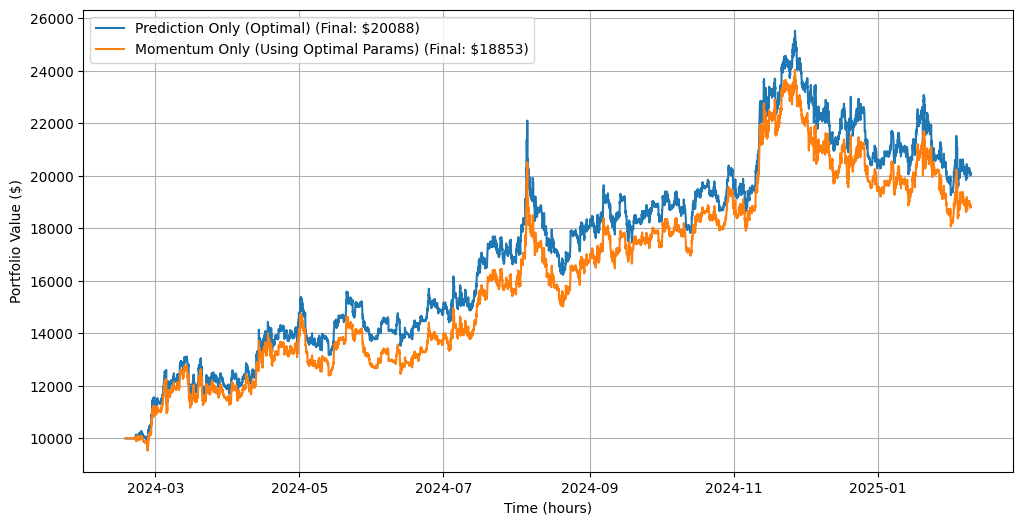

In [ ]:
lookback_range = range(1, 24*7, 1)
hold_hours_range = range(1, 24*7, 1)
signal_strength_thresholds = np.arange(0.1, 0.3, 0.1)

best_lookback = 0
best_hold_hours = 0
best_signal_strength_threshold = 0
#best_target_risk = 0
initial_capital_opt = 10000
best_final_capital_opt = initial_capital_opt

for lookback in lookback_range:
  for hold_hours in hold_hours_range:
    for signal_strength_threshold in signal_strength_thresholds:
      try:
          final_capital, _, _, _ = backtest_ts_momentum(
              close_price,
              predicted_changes=val_pred_1h_change,
              mode='prediction_only',
              lookback=lookback,
              vol_window=24,
              hold_hours=hold_hours,
              target_risk_per_trade=best_target_risk,
              signal_strength_threshold=signal_strength_threshold,
              transaction_cost_pct=fixed_transaction_cost_pct
          )
          if final_capital > best_final_capital_opt:
              best_final_capital_opt = final_capital
              best_lookback = lookback
              best_hold_hours = hold_hours
              best_signal_strength_threshold = signal_strength_threshold
              #best_target_risk = target_risk
      except ValueError as e:
            print(f"Skipping Lookback: {lookback} hours, Target Risk: {target_risk:.2f}% due to error: {e}")


print(f"\n Optimal best_lookback: {best_lookback}")
print(f"\n Optimal best_hold_hours: {best_hold_hours}")
print(f"\n Optimal best_signal_strength_threshold: {best_signal_strength_threshold}")
print(f"\n best_final_capital_opt: {best_final_capital_opt}")
#print(f"Optimal Target Risk Per Trade: {best_target_risk:.2f}%")
#print(f"Final Capital with Optimal Parameters and {fixed_transaction_cost_pct_opt}% Transaction Cost: ${best_final_capital_opt:.2f}")


final_capital_optimal, portfolio_history_optimal, _, _ = backtest_ts_momentum(
    close_price,
    predicted_changes=val_pred_1h_change,
    mode='prediction_only',
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    signal_strength_threshold=best_signal_strength_threshold,
    transaction_cost_pct=fixed_transaction_cost_pct
)

final_mom, hist_mom, _, _ = backtest_ts_momentum(
    close_price,
    predicted_changes=None,
    mode='momentum_only',
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    signal_strength_threshold=best_signal_strength_threshold,
    transaction_cost_pct=fixed_transaction_cost_pct
)


plt.figure(figsize=(12,6))
plot_index_optimal = df_hourly.index[len(df_hourly)-len(portfolio_history_optimal):]
plt.plot(plot_index_optimal, portfolio_history_optimal, label=f'Prediction Only (Optimal) (Final: ${final_capital_optimal:.0f})')

plot_index_mom = df_hourly.index[len(df_hourly)-len(hist_mom):]
plt.plot(plot_index_mom, hist_mom, label=f'Momentum Only (Using Optimal Params) (Final: ${final_mom:.0f})')


#plt.title(f'Time-Series Momentum Backtesting with {fixed_transaction_cost_pct_opt}% Transaction Cost')
plt.xlabel('Time (hours)')
plt.ylabel('Portfolio Value ($)')
plt.legend()
plt.grid(True)
plt.show()


 Optimal best_lookback: 96

 Optimal best_hold_hours: 159

 Optimal best_signal_strength_threshold: 0.28000000000000014

 best_final_capital_opt: 20582.60078932818
388
351


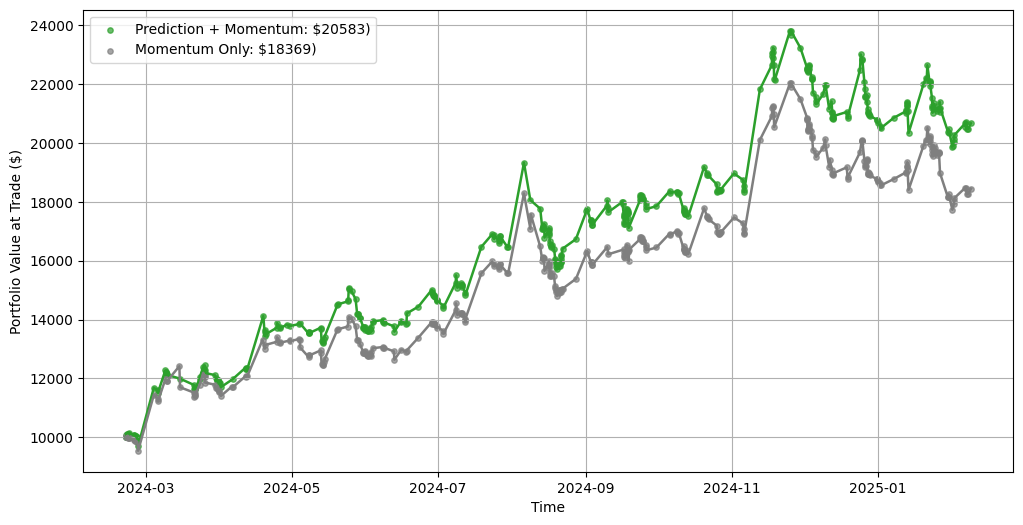

In [ ]:

signal_strength_thresholds = np.arange(0.15, 0.3, 0.01)

best_signal_strength_threshold = 0
#best_target_risk = 0
initial_capital_opt = 10000
best_final_capital_opt = initial_capital_opt

for signal_strength_threshold in signal_strength_thresholds:
    final_capital, _, _, _ = backtest_ts_momentum(
        close_price,
        predicted_changes=val_pred_1h_change,
        mode='prediction_only',
        lookback=best_lookback,
        vol_window=24,
        hold_hours=best_hold_hours,
        target_risk_per_trade=best_target_risk,
        signal_strength_threshold=signal_strength_threshold,
        transaction_cost_pct=fixed_transaction_cost_pct
    )
    if final_capital > best_final_capital_opt:
        best_final_capital_opt = final_capital
        best_signal_strength_threshold = signal_strength_threshold
        #best_target_risk = target_risk


print(f"\n Optimal best_lookback: {best_lookback}")
print(f"\n Optimal best_hold_hours: {best_hold_hours}")
print(f"\n Optimal best_signal_strength_threshold: {best_signal_strength_threshold}")
print(f"\n best_final_capital_opt: {best_final_capital_opt}")
#print(f"Optimal Target Risk Per Trade: {best_target_risk:.2f}%")
#print(f"Final Capital with Optimal Parameters and {fixed_transaction_cost_pct_opt}% Transaction Cost: ${best_final_capital_opt:.2f}")


final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt = backtest_ts_momentum(
    close_price,
    predicted_changes=val_pred_1h_change,
    mode='prediction_only',
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    signal_strength_threshold=best_signal_strength_threshold,
    transaction_cost_pct=fixed_transaction_cost_pct
)

final_mom, hist_mom, trade_times_mom, trade_values_mom = backtest_ts_momentum(
    close_price,
    predicted_changes=None,
    mode='momentum_only',
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    signal_strength_threshold=best_signal_strength_threshold,
    transaction_cost_pct=fixed_transaction_cost_pct
)

plt.figure(figsize=(12,6))

print(len(trade_times_opt))
print(len(trade_times_mom))


trade_dates_opt = [df_hourly.index[len(df_hourly)-len(portfolio_history_optimal)+t] for t in trade_times_opt]
plt.scatter(trade_dates_opt, trade_values_opt,
            label=f'Prediction + Momentum: ${final_capital_optimal:.0f})',
            marker='o', s=15, alpha=0.7, color='tab:green')
# Connect prediction trades with a thin line
plt.plot(trade_dates_opt, trade_values_opt, '-', color='tab:green', linewidth=1.8, alpha=1)


trade_dates_mom = [df_hourly.index[len(df_hourly)-len(hist_mom)+t] for t in trade_times_mom]
plt.scatter(trade_dates_mom, trade_values_mom,
            label=f'Momentum Only: ${final_mom:.0f})',
            marker='o', s=15, alpha=0.7, color='tab:gray')
# Connect momentum trades with a thin line
plt.plot(trade_dates_mom, trade_values_mom, '-', color='tab:gray', linewidth=1.8, alpha=1)

plt.xlabel('Time')
plt.ylabel('Portfolio Value at Trade ($)')
plt.legend()
plt.grid(True)
plt.show()